<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Contexte-de-l'étude" data-toc-modified-id="Contexte-de-l'étude-1">Contexte de l'étude</a></span></li><li><span><a href="#Préparation-des-bases-de-données" data-toc-modified-id="Préparation-des-bases-de-données-2">Préparation des bases de données</a></span><ul class="toc-item"><li><span><a href="#Importation-des-librairies-et-fonctions-personnalisées" data-toc-modified-id="Importation-des-librairies-et-fonctions-personnalisées-2.1">Importation des librairies et fonctions personnalisées</a></span></li><li><span><a href="#Importation-des-jeux-de-données" data-toc-modified-id="Importation-des-jeux-de-données-2.2">Importation des jeux de données</a></span></li><li><span><a href="#Récapitulatif-des-bases-de-données" data-toc-modified-id="Récapitulatif-des-bases-de-données-2.3">Récapitulatif des bases de données</a></span></li></ul></li><li><span><a href="#Analyses-descriptives" data-toc-modified-id="Analyses-descriptives-3">Analyses descriptives</a></span><ul class="toc-item"><li><span><a href="#Correlation-de-Pearson" data-toc-modified-id="Correlation-de-Pearson-3.1">Correlation de Pearson</a></span></li><li><span><a href="#Analyse-en-composantes-principales-(ACP)" data-toc-modified-id="Analyse-en-composantes-principales-(ACP)-3.2">Analyse en composantes principales (ACP)</a></span></li><li><span><a href="#Partitionner-avec-l'algorithme--k-means" data-toc-modified-id="Partitionner-avec-l'algorithme--k-means-3.3">Partitionner avec l'algorithme  k-means</a></span></li></ul></li><li><span><a href="#Analyses-explicatives" data-toc-modified-id="Analyses-explicatives-4">Analyses explicatives</a></span><ul class="toc-item"><li><span><a href="#une-variable-quantitative-et-une-variable-qualitative-:-ANOVA" data-toc-modified-id="une-variable-quantitative-et-une-variable-qualitative-:-ANOVA-4.1">une variable quantitative et une variable qualitative : ANOVA</a></span></li><li><span><a href="#Deux-variables-qualitatives-:-CHI-2" data-toc-modified-id="Deux-variables-qualitatives-:-CHI-2-4.2">Deux variables qualitatives : CHI-2</a></span></li></ul></li><li><span><a href="#Conclusion" data-toc-modified-id="Conclusion-5">Conclusion</a></span></li></ul></div>

# Contexte de l'étude

Ce notebook présente la réalisation d'une première exploration et analyse des données. 

L'analyse est basée sur le jeu de données Open Food Facts.

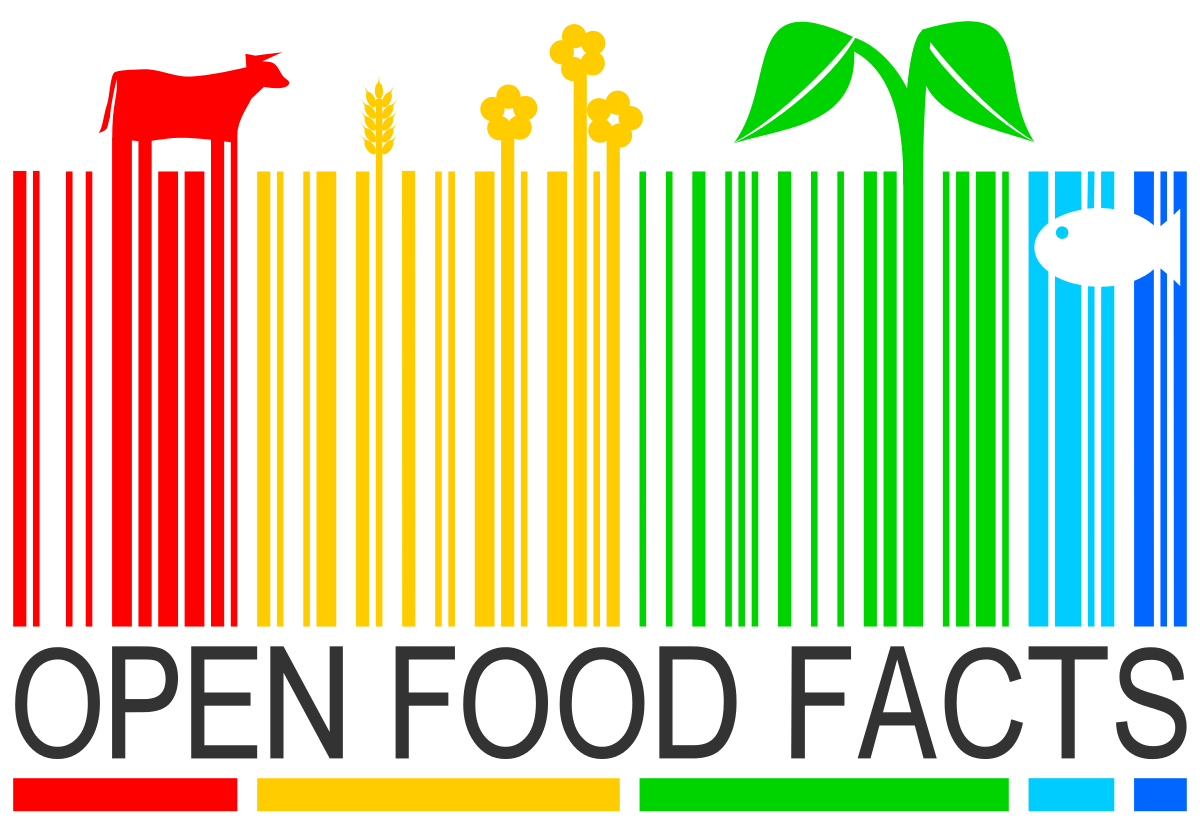

# Préparation des bases de données

## Importation des librairies et fonctions personnalisées

Les librairies nécessaires pour l'étude sont importées dans l'environnement de travail.

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import datetime  # Manipuler dates et heures

In [2]:
from my_functions import *

## Importation des jeux de données

In [3]:
chemin = "C:/Users/smora/Desktop/Les projets OC/Projet 03/Données"

In [4]:
df_net = pd.read_csv(chemin + "/export_df_net.csv", sep='\t', low_memory=False)
compte_additifs = pd.read_csv(chemin + "/export_compte_additifs.csv",
                              sep='\t',
                              low_memory=False)
compte_ingredients = pd.read_csv(chemin + "/export_compte_ingredients.csv",
                                 sep='\t',
                                 low_memory=False)
data_pnns = pd.read_csv(chemin + "/export_data_pnns.csv",
                        sep='\t',
                        low_memory=False)
data_packaging = pd.read_csv(chemin + "/export_data_packaging.csv",
                             sep='\t',
                             low_memory=False)
data_matiere = pd.read_csv(chemin + "/export_data_matiere.csv",
                           sep='\t',
                           low_memory=False)

## Récapitulatif des bases de données

In [5]:
df_net.head()  #Base de données principale

,code,created_t,product_name,brands_tags,labels_tags,serving_quantity,additives_n,ingredients_from_palm_oil_n,ingredients_that_may_be_from_palm_oil_n,nutriscore_score,...,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,countries,solide_ou_liquide,year,boisson_ou_aliment,score_fruits_vegetables
0,0000000000017,1529059080,Vitória crackers,unknown,Unknown,2.040371e+08,2,0,0,14.0,...,0.560,0.012460,0.077388,0.144409,0.015516,France,Unknown,2018,aliment,0
1,000000000003327986,1574175736,Filetes de pollo empanado,unknown,Unknown,2.040371e+08,2,0,0,9.0,...,0.440,0.012460,0.077388,0.144409,0.015516,Espagne,Unknown,2019,aliment,0
2,000000000004622327,1619501895,Hamburguesas de ternera 100%,unknown,Unknown,2.040371e+08,2,0,0,17.0,...,0.840,0.012460,0.077388,0.144409,0.015516,Espagne,Unknown,2021,aliment,0
3,0000000000100,1444572561,moutarde au moût de raisin,courte-paille,Autre,3.369091e+01,0,0,0,18.0,...,1.840,0.000103,0.005671,0.041014,0.000623,France,Solide,2015,aliment,0
4,0000000000123,1535737982,Sauce Sweety chili 0%,unknown,Unknown,2.040371e+08,2,0,0,-3.0,...,0.816,0.012460,0.077388,0.144409,0.015516,France,Unknown,2018,aliment,0


In [6]:
df_description = data_informations(df_net)

---------------------------INFORMATION SUR LA BASE DE DONNEES-----------------------------------------------
Nombre de variables : 37
Nombre d'observations : 1527078
---------------------------VALEURS MANQUANTES---------------------------------------------------------------
Nombre de cellules avec des données manquantes :  2
Pourcentage du nombre de cellules avec des données manquantes :  0.0  %
Nombre de lignes avec au moins une donnée manquante :  2
Pourcentage de lignes avec au moins une donnée manquante :  0.0  %
---------------------------VALEURS DUPLIQUEES---------------------------------------------------------------
Nombre de doublons dans la base de données :  0
Pourcentage de doublons dans la base de données :  0.0  %
---------------------------VALEURS OUTLIERS-----------------------------------------------------------------
Nombre de cellules avec des outliers :  1853986
Pourcentage du nombre de cellules avec des outliers :  3.3  %
Nombre de lignes avec au moins un outlier :

In [7]:
compte_additifs.head(
)  #Base de données qui donne le nombre d'additifs dans l'ensemble de la base de données df_net

,Nom_Additif,Nombre
0,Unknown,1144572
1,E330,124179
2,E322,84627
3,E322i,76841
4,E500,53888


In [8]:
compte_ingredients['Nom_Ingredient'] = compte_ingredients[
    'Nom_Ingredient'].str.lower()
compte_ingredients.head(
)  #Base de données qui donne le nombre d'additifs dans l'ensemble de la base de données df_net

,Nom_Ingredient,Nombre
0,unknown,890533
1,salt,355047
2,sugar,200259
3,water,182810
4,citric acid,52588


In [9]:
data_pnns.head()

,Groupement 02,Nombre,Groupement 01
0,unknown,873484,unknown
1,Sweets,62081,Sugary snacks
2,Biscuits and cakes,59855,Sugary snacks
3,Dressings and sauces,45507,Fat and sauces
4,One-dish meals,40077,Composite foods


# Analyses descriptives

## Correlation de Pearson

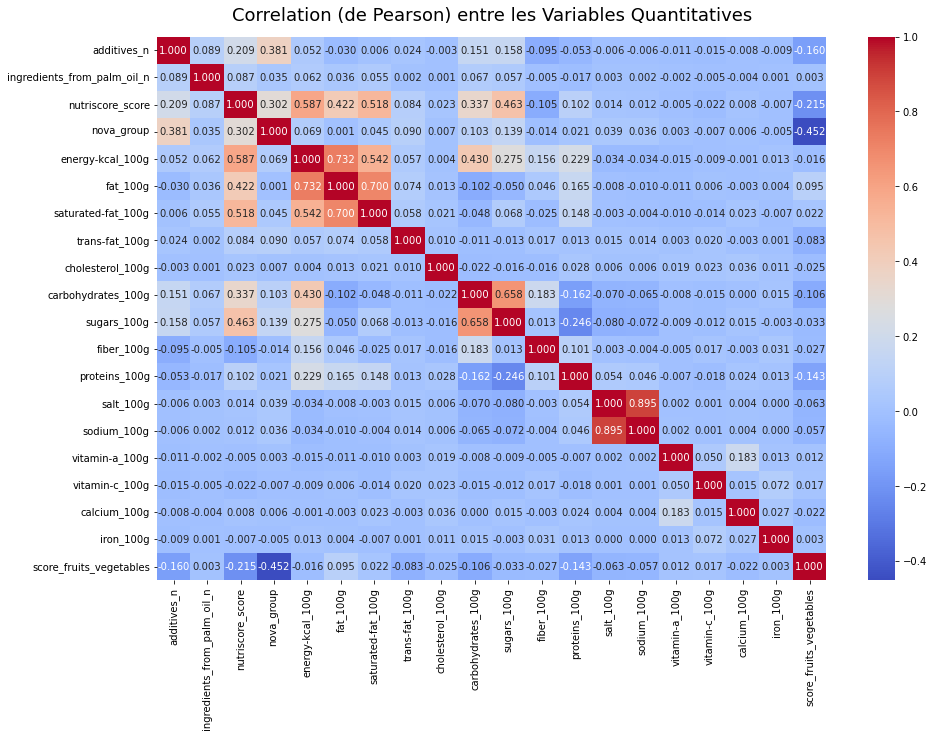

In [10]:
correlation_map_corr(df_net)

La heatmap ci-dessous donne les coefficients de corrélation de Pearson pour chaque couple de variables quantitatives.
Cette corrélation est linéaire, le coefficient est proche de 1 quand les variables partagent une forte corrélation linéaire.

## Analyse en composantes principales (ACP)

L'Analyse en composantes principales nous permet d'effectuer une réduction de dimension et de déceler des dépendances entre des variables.

In [11]:
df_net = df_net.drop(columns=[
    'created_t', 'energy_100g', 'serving_quantity',
    'ingredients_that_may_be_from_palm_oil_n', 'year'
])

In [12]:
data_pca = df_net.copy(deep=True)
data_pca = data_pca.drop(columns=[
    'score_fruits_vegetables', 'sodium_100g', 'saturated-fat_100g',
    'carbohydrates_100g'
])

print(
    f"La base de données contient {data_pca.select_dtypes(exclude=object).shape[1]} variables quantitatives"
)

La base de données contient 16 variables quantitatives


In [13]:
pca, data_compo, n_comp, X_projected, names = maPCA(
    data_pca,
    data_pca.select_dtypes(exclude=object).shape[1])

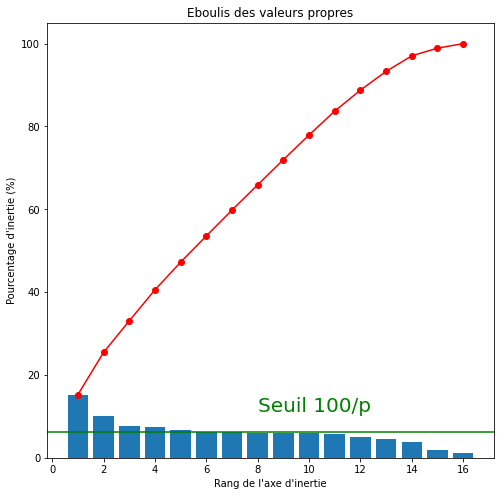

D'après le critère de Kaiser, il y a 6 composantes principales optimales (avec un pourcentage d'inertie supérieur au seuil de 100/p).


In [14]:
eboulis(pca, data_pca.select_dtypes(exclude=object).shape[1], n_comp)

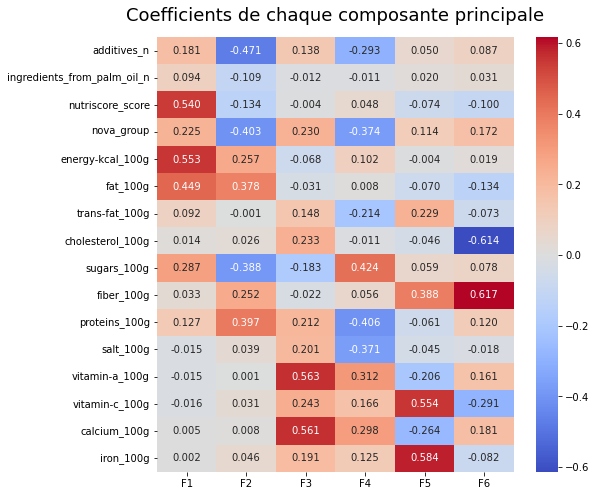

In [15]:
pca, data_compo, n_comp, X_projected, names = maPCA(data_pca, 6)

La fonction de l'ACP donne également le tableau de valeur selon les nouvelles "variables" que sont les composantes principales.

In [16]:
data_compo.head()

,F1,F2,F3,F4,F5,F6
0,0.642740,-0.266554,0.096669,-0.030729,0.184922,0.163366
1,-0.531045,-0.045014,0.450262,-0.731412,0.176831,0.294280
2,2.442821,1.180654,0.240600,-0.444187,0.010986,0.153695
3,0.371162,-0.560237,-0.278843,0.115846,-0.592942,-0.665881
4,-2.070200,-0.646187,0.248235,-0.383116,0.377463,0.235699


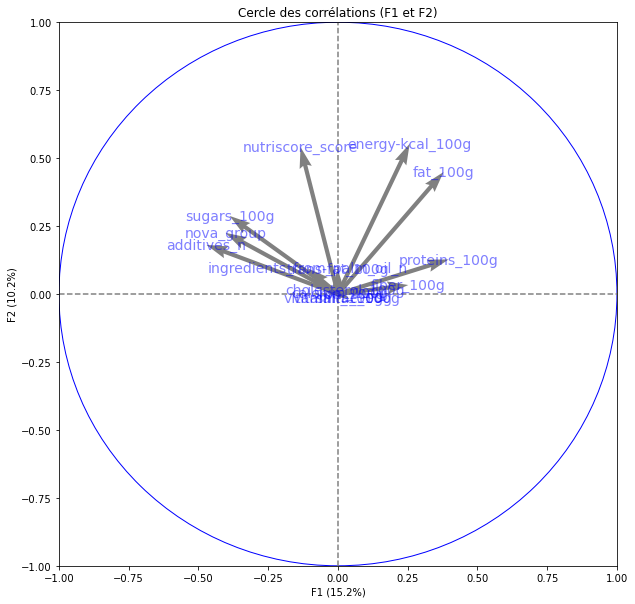

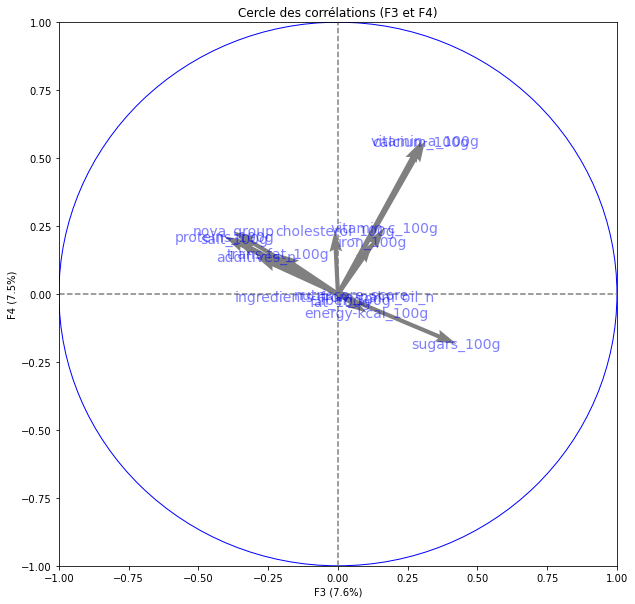

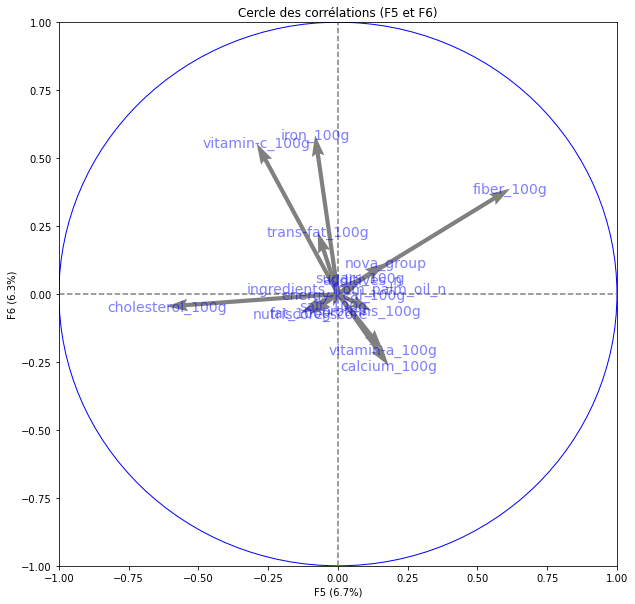

In [17]:
features = data_pca.select_dtypes(exclude=object).columns
display_circles(n_comp,
                pca, [(0, 1), (2, 3), (4, 5)],
                labels=np.array(features))

Enfin, il est possible de représenter les produits sur les graphiques avec comme axes les composantes principales. 

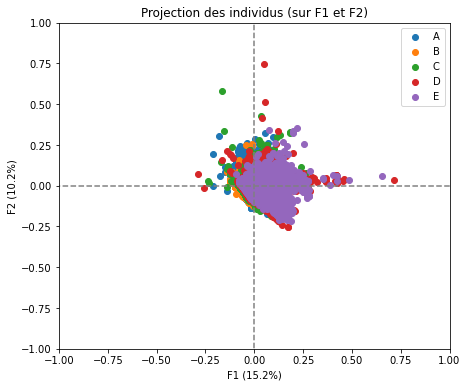

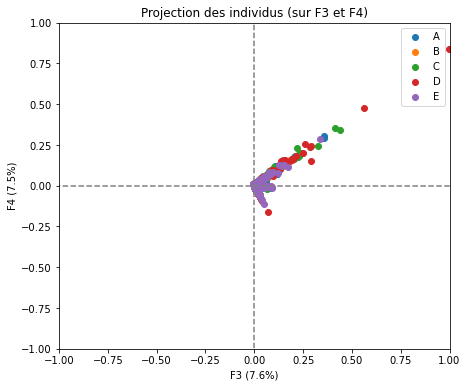

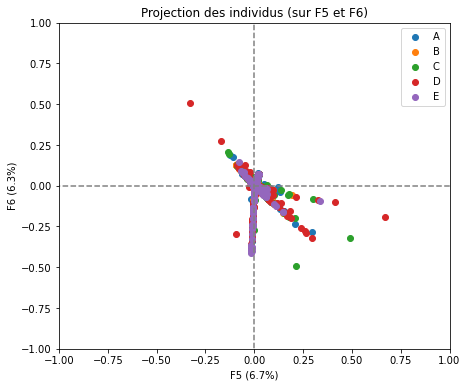

In [18]:
display_factorial_planes(X_projected,
                         n_comp,
                         pca, [(0, 1), (2, 3), (4, 5)],
                         illustrative_var=data_pca['nutriscore_grade'])

## Partitionner avec l'algorithme  k-means

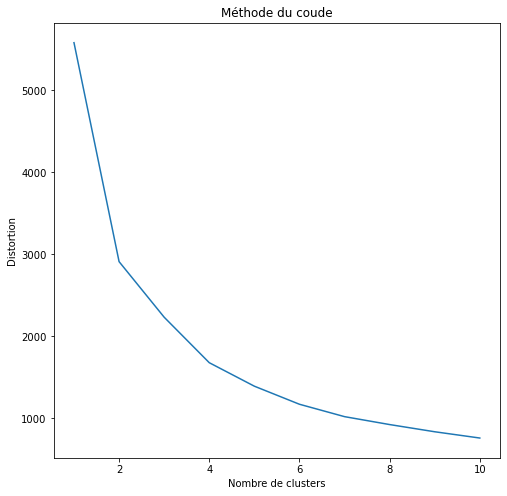

In [19]:
methode_coude(X_projected)

In [20]:
data_pca['cluster_Kmeans'] = clusters(6, X_projected, data_pca)

La segmentation des données est faite grâce aux fonctions Kmeans. Les différents produits de la base de données sont partagés en sous-groupes en fonction de leur projection sur les composantes principales. 

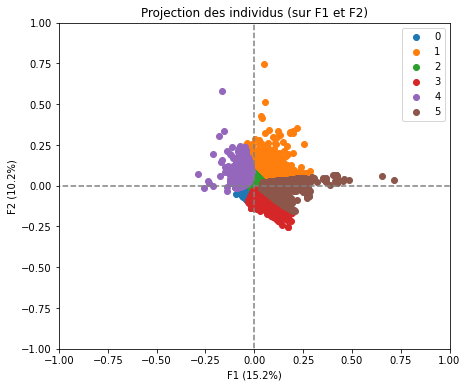

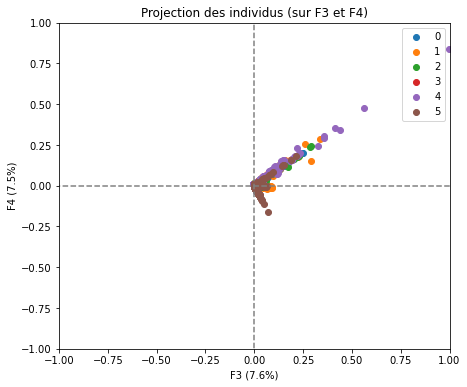

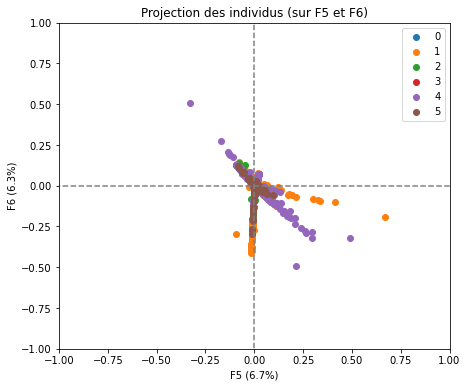

In [21]:
display_factorial_planes(X_projected,
                         n_comp,
                         pca, [(0, 1), (2, 3), (4, 5)],
                         illustrative_var=data_pca['cluster_Kmeans'])

Contrairement aux représentations précédentes, les groupes sont ici visibles, notamment sur la représentation des projections sur les composantes F1 et F2. 
Cette association de l'analyse en composantes principales avec l'algorithme de k-means représente une opportunitée pour commencer une classification non supervisée. Cette classification pourra ensuite être utilisée par des algorithmes pour prédire des valeurs de variables telles que les valeurs d'un nutriscore ou pour savoir à quel groupe d'aliments appartient un produit à partir de ces variables quantitatives.

# Analyses explicatives

## une variable quantitative et une variable qualitative : ANOVA

Les tests ANOVA permettent de comparer des variables quantitatives à des variables qualitatives. Une partie des variables est sélectionnée pour ces tests.

In [22]:
columns_quali = [
    'labels_tags', 'nutriscore_grade', 'pnns_groups_1', 'countries'
]
columns_quanti = [
    'nutriscore_score', 'energy-kcal_100g', 'fat_100g', 'sugars_100g',
    'fiber_100g', 'proteins_100g', 'salt_100g'
]
df_anova = df_net[columns_quali + columns_quanti]

La corrélation entre des variables quantitatives et des variables qualitatives peut être observée grâce à des représentations de type pairplot.

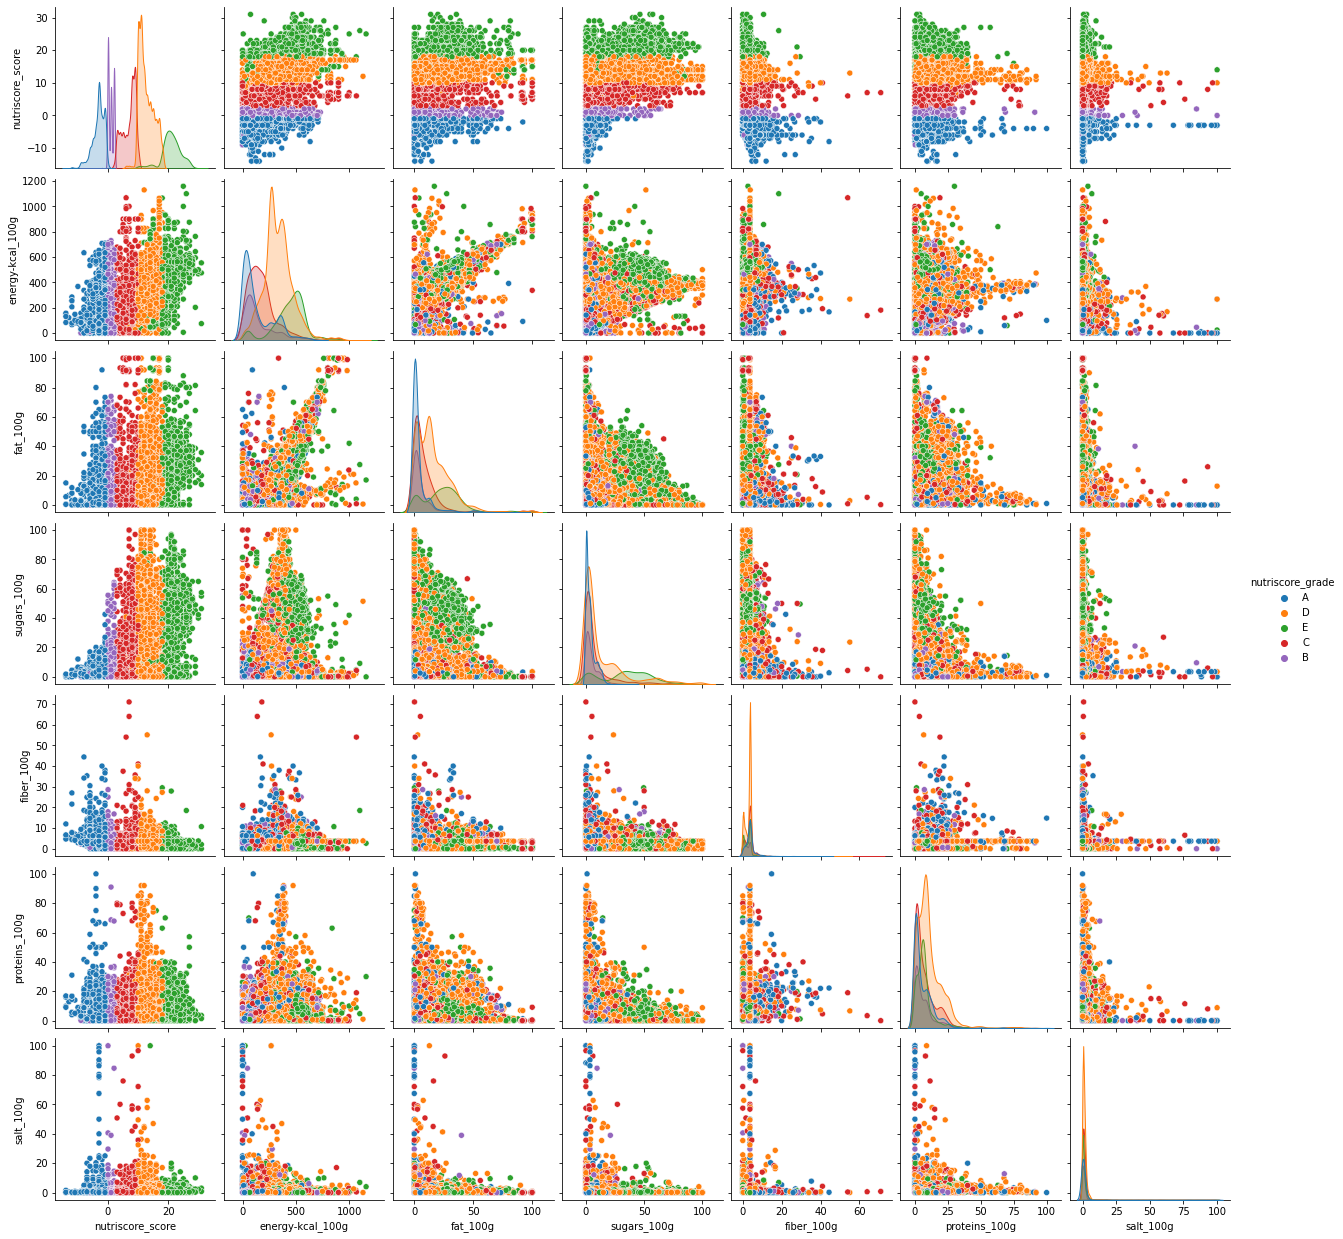

In [23]:
sns.pairplot(df_anova.sample(frac=0.01), hue="nutriscore_grade")
plt.show()

Sur ces représentations, il est possible de voir une répartition des nutriscore_grade en fonction des valeurs de sugars_100g, fat_100g et energy-kcal_100g.

Une autre façon de visualiser des corrélations entre les variables qualitatives et les variables quantitatives est de représenter des boxplots des variables quantitatives en fonction des modalités des variables qualitatives.

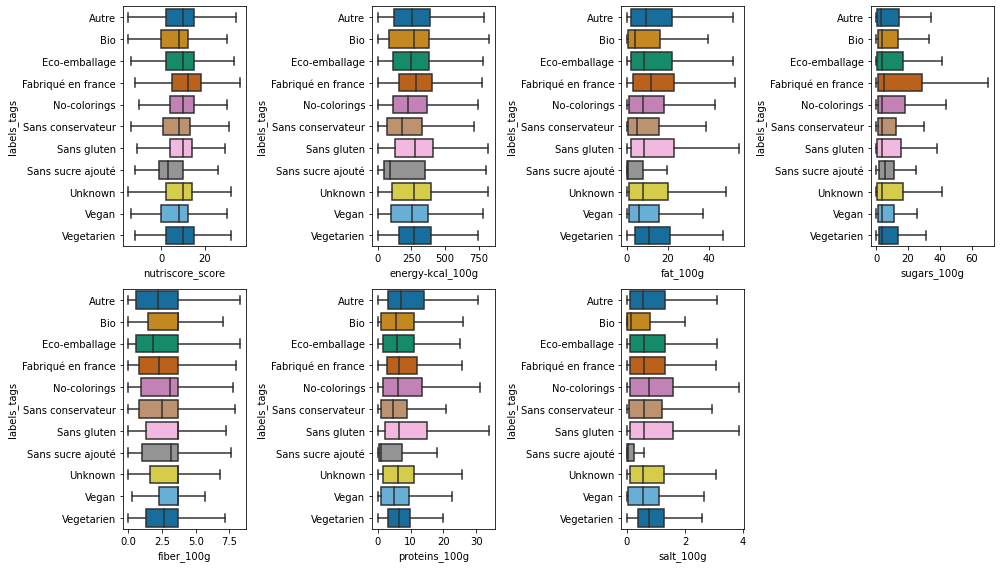

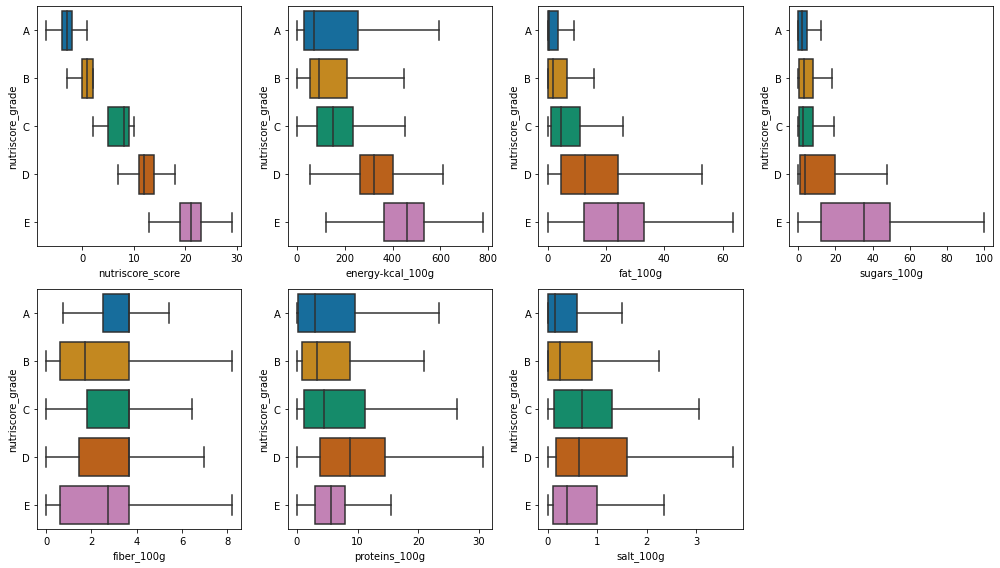

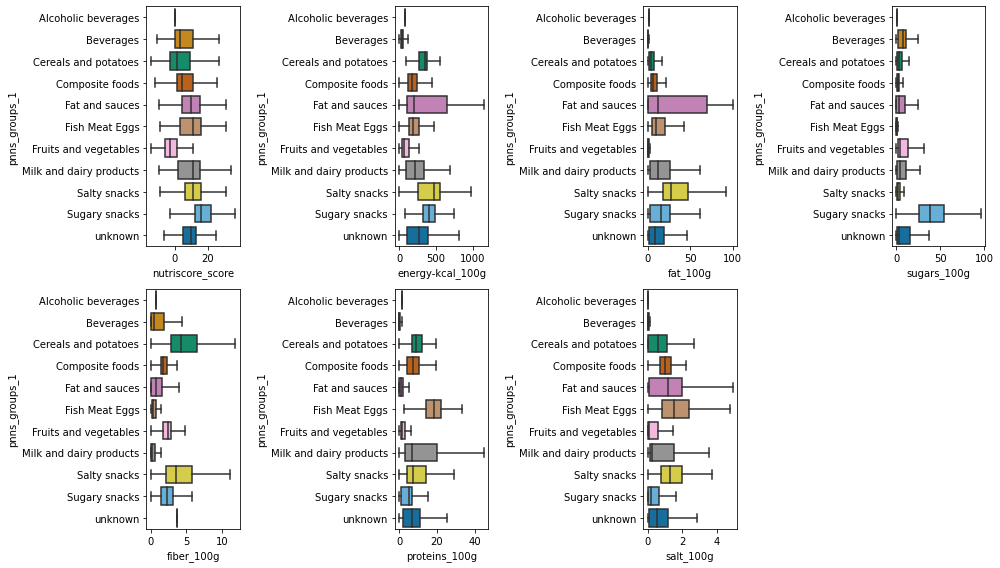

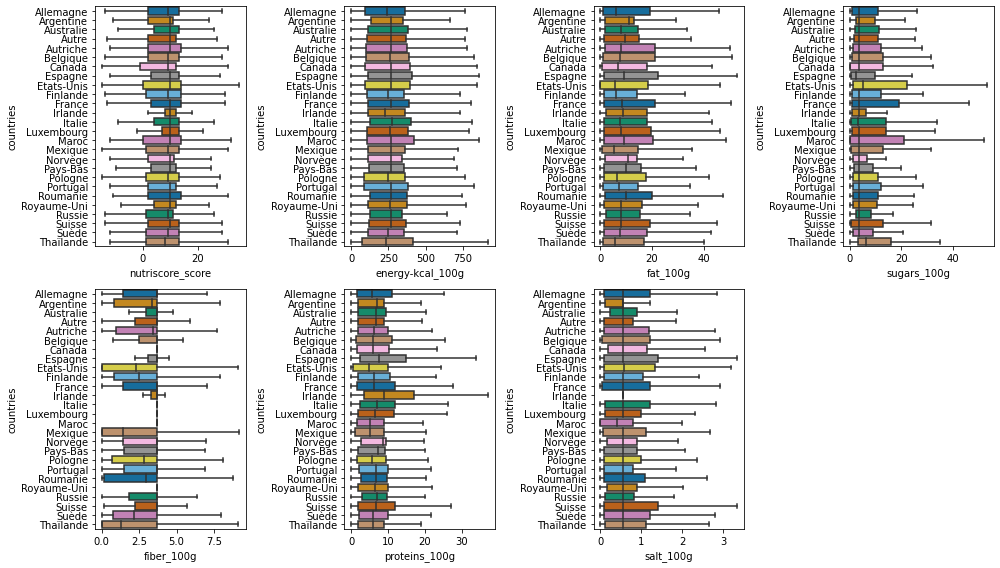

In [27]:
moust_aqui(df_anova, columns_quali, columns_quanti)

In [28]:
data_eta = tableau_eta(df_anova, columns_quali, columns_quanti)

Le tableau ci-dessous représente les rapports de corrélation (Variation interclasses / Variation totale) pour chaque couple de variables.

In [29]:
df_resultat = pd.DataFrame(data_eta, index=columns_quali)
display(df_resultat)

,nutriscore_score,energy-kcal_100g,fat_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g
labels_tags,0.008,0.002,0.001,0.001,0.009,0.004,0.001
nutriscore_grade,0.909,0.325,0.153,0.239,0.031,0.042,0.002
pnns_groups_1,0.199,0.165,0.132,0.240,0.177,0.146,0.011
countries,0.004,0.002,0.002,0.009,0.005,0.008,0.002


Plus le rapport de corrélation est proche de 1, plus les variables sont fortement corrélées. 

Les deux hypothèses du test ANOVA effectué sur cette étude sont :
- H0 : les distributions suivent la même loi normale. 
- H1 : il existe au moins une distribution dont la moyenne s'écarte des autres moyennes.

Avant de lancer un test ANOVA, il est indispensable de vérifier si les variables quantitatives répondent à une loi normale.

In [30]:
test_anova_data(df_anova)

________
nutriscore_score
p = 0
H0 est rejetée : nutriscore_score n'est pas de distribution normale
________
energy-kcal_100g
p = 0
H0 est rejetée : energy-kcal_100g n'est pas de distribution normale
________
fat_100g
p = 0
H0 est rejetée : fat_100g n'est pas de distribution normale
________
sugars_100g
p = 0
H0 est rejetée : sugars_100g n'est pas de distribution normale
________
fiber_100g
p = 0
H0 est rejetée : fiber_100g n'est pas de distribution normale
________
proteins_100g
p = 0
H0 est rejetée : proteins_100g n'est pas de distribution normale
________
salt_100g
p = 0
H0 est rejetée : salt_100g n'est pas de distribution normale


Pour chaque variable quantitative, l'hypothèse de distribution normale est rejétée. Les résultats des tests ANOVA seront donc à prendre avec précautions.

In [31]:
table_anova('nutriscore_score ~ C(pnns_groups_1)', df_anova)

,sum_sq,df,F,PR(>F)
C(pnns_groups_1),1.951734e+07,10.0,38051.353704,0.0
Residual,7.832649e+07,1527067.0,NaN,NaN


In [32]:
table_anova('nutriscore_score ~ C(countries)', df_anova)

,sum_sq,df,F,PR(>F)
C(countries),4.257988e+05,25.0,266.980075,0.0
Residual,9.741804e+07,1527052.0,NaN,NaN


In [33]:
table_anova('nutriscore_score ~ C(labels_tags)', df_anova)

,sum_sq,df,F,PR(>F)
C(labels_tags),7.464292e+05,10.0,1173.921621,0.0
Residual,9.709741e+07,1527067.0,NaN,NaN


In [34]:
table_anova('nutriscore_score ~ C(nutriscore_grade)', df_anova)

,sum_sq,df,F,PR(>F)
C(nutriscore_grade),8.895511e+07,4.0,3.820597e+06,0.0
Residual,8.888726e+06,1527073.0,NaN,NaN


Les tests d'indépendance (test de Fisher) de chacune des variables qualitatives donnent une p-value inférieure à 0.05 (niveau de test = 5%). L'hypothèse H0 selon laquelle les distributions par modalité présentent une similarité est rejetée. Cela signifie qu'il y a une dépendance entre les variables quantitatives et les variables qualitatives.

## Deux variables qualitatives : CHI-2

Le test du CHI-2 (ou KHI-2) est utilisé ici pour avoir une idée de la dépendance des variables qualitatives. Dans cette partie, seule la corrélation entre le nutriscore et les autres variables qualitatives sera étudiée.

In [ ]:
columns_quali = [
    'labels_tags', 'nutriscore_grade', 'pnns_groups_1', 'countries'
]
columns_quali_sans_nutri = ['labels_tags', 'pnns_groups_1', 'countries']
df_chi_2 = df_net[columns_quali]
df_chi_2['pnns_groups_1'] = df_chi_2['pnns_groups_1'].str.capitalize()

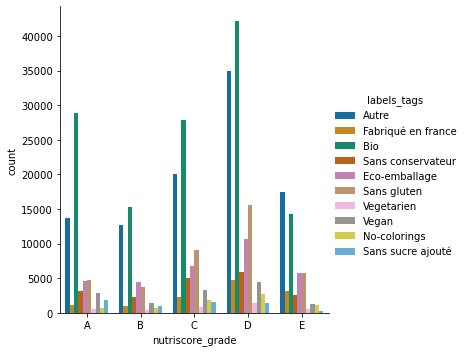

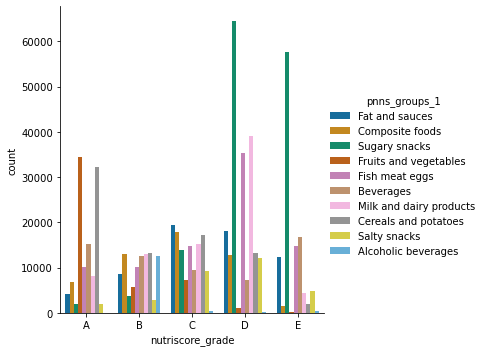

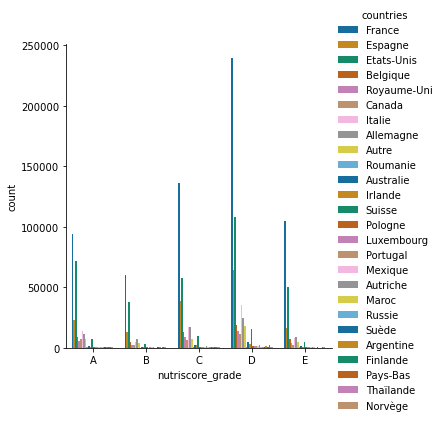

In [36]:
visu_chi2(df_chi_2, columns_quali_sans_nutri)

D'abord, un tableau de contingence est affiché pour chacune des variables. Il s'agit tu tableau où apparaissent les $n_{ij}$.

In [37]:
for column in columns_quali_sans_nutri:
    tableau = tableau_contingence_XY(df_chi_2, 'nutriscore_grade', column)

labels_tags,Autre,Bio,Eco-emballage,Fabriqué en france,No-colorings,Sans conservateur,Sans gluten,Sans sucre ajouté,Unknown,Vegan,Vegetarien
nutriscore_grade,,,,,,,,,,,
A,13708,28924,4570,1142,668,3198,4815,1832,197370,2881,541
B,12718,15365,4510,1031,772,2363,3803,984,102374,1465,460
C,20033,27802,6813,2316,1844,5001,9130,1590,248186,3309,886
D,34929,42156,10657,4755,2748,5876,15618,1486,451934,4512,1412
E,17418,14252,5748,3122,1095,2545,5804,332,166544,1222,509


pnns_groups_1,Alcoholic beverages,Beverages,Cereals and potatoes,Composite foods,Fat and sauces,Fish meat eggs,Fruits and vegetables,Milk and dairy products,Salty snacks,Sugary snacks,Unknown
nutriscore_grade,,,,,,,,,,,
A,78,15196,32141,6910,4071,10057,34475,8198,2060,1968,144495
B,12588,12622,13304,13100,8554,10145,5668,13023,2867,3756,50218
C,315,9451,17134,17888,19465,14669,7256,15319,9279,13811,202323
D,89,7241,13304,12796,18074,35302,1096,39058,12162,64469,372492
E,469,16729,2069,1559,12391,14671,114,4346,4731,57555,103957


countries,Allemagne,Argentine,Australie,Autre,Autriche,Belgique,Canada,Espagne,Etats-Unis,Finlande,...,Norvège,Pays-Bas,Pologne,Portugal,Roumanie,Royaume-Uni,Russie,Suisse,Suède,Thaïlande
nutriscore_grade,,,,,,,,,,,,,,,,,,,,,
A,11422,382,1833,7047,755,8611,7659,22880,71915,385,...,276,725,592,495,286,5416,447,7350,524,423
B,6999,295,915,3884,610,4474,2309,13322,37475,280,...,191,370,615,297,252,2565,267,3190,407,376
C,17209,368,2721,7646,1239,12825,6386,38626,58045,475,...,441,1045,906,658,331,9016,587,9407,685,480
D,24748,1320,5191,18198,1972,18902,11252,64224,107972,675,...,779,2171,1384,1220,788,14152,1057,15944,1101,673
E,8986,244,1278,4579,780,6923,2667,16361,49915,282,...,184,457,510,294,304,3612,167,5001,390,344


In [38]:
for column in columns_quali_sans_nutri:
    tableau = test_chi_2_XY(df_chi_2, 'nutriscore_grade', column)

La p-value pour le test du CHI-2 entre la variable  nutriscore_grade et la variable  labels_tags est  0.0
H0 rejetée : les variables  nutriscore_grade et  labels_tags  ne sont pas indépendantes
La p-value pour le test du CHI-2 entre la variable  nutriscore_grade et la variable  pnns_groups_1 est  0.0
H0 rejetée : les variables  nutriscore_grade et  pnns_groups_1  ne sont pas indépendantes
La p-value pour le test du CHI-2 entre la variable  nutriscore_grade et la variable  countries est  0.0
H0 rejetée : les variables  nutriscore_grade et  countries  ne sont pas indépendantes


Il est possible d'afficher une heatmap qui traduit le rapport entre les tableaux des $n_{ij}$  et les tableaux des $f_{i}$ x $n_{j}$. La couleur la plus claire représente un couple de modalités dont le rapport entre la mesure statistique locale et la mesure statistique globale est proche de 1. Les couples de modalités en foncé sont ceux qui ont un écart entre leur mesure et leur valeur d'indépendance élevé.

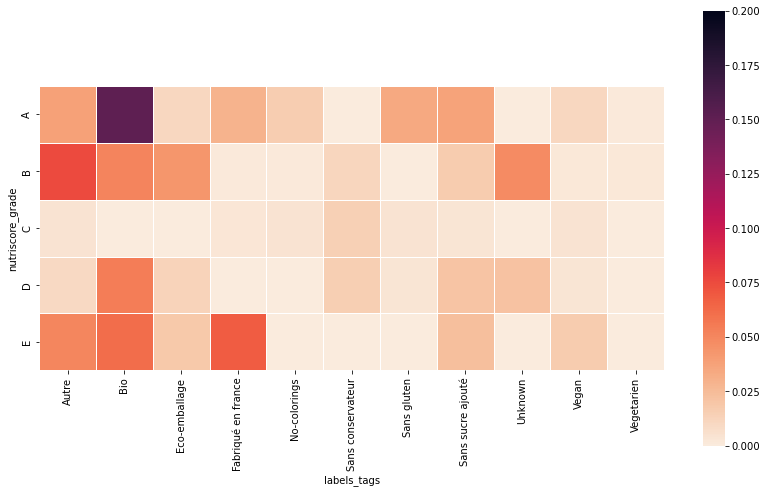

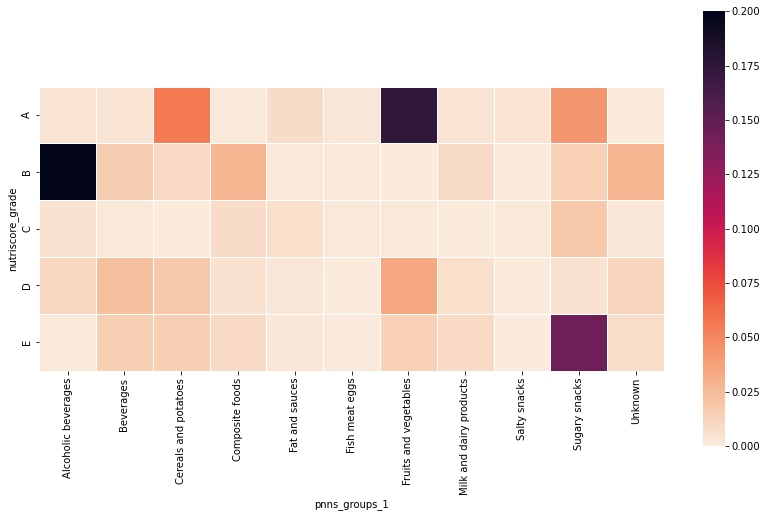

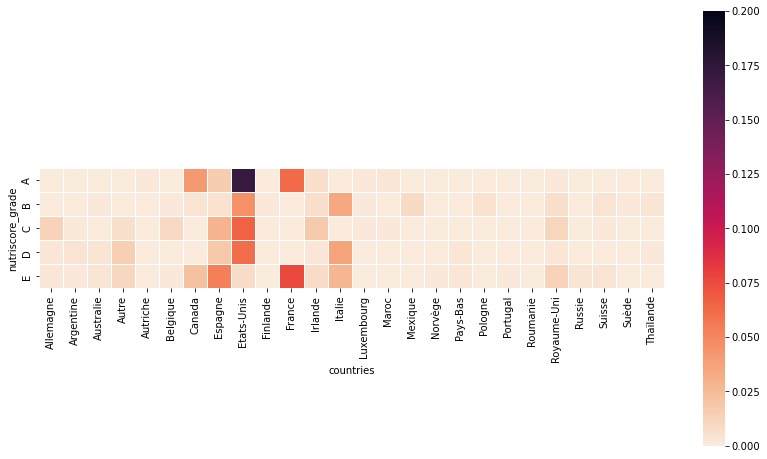

In [39]:
for column in columns_quali_sans_nutri:
    tableau_chi_2_color(df_chi_2, 'nutriscore_grade', column)

Les différentes heatmap corroborent bien la dépendance entre les variables qualitatives (qui était déjà établie avec le test du CHI-2)

# Conclusion

L'étude présentée dans ce notebook a permis de répondre à plusieurs objectifs.

La base de données a été nettoyée pour ne garer que les variables les plus pertinentes. Elle a été débarrassée de ses doublons, des produits impossibles à identifiés et des lignes complètement vides. Les valeurs impossibles des variables quantitatives ont été supprimées. Pour finir, les valeurs manquantes ont ensuite été imputées grâce aux données statistiques des différentes variables.

Les variables ont d’abord été visualisées une part une avec une représentation adéquate quant à leur distribution. Les visualisations interactives ont permis par la suite de présenter de plus en plus de variables sur un même support. De ces représentations sont venus les premières hypothèses de corrélations entre les variables.

Ces hypothèses ont été validées d’abord par la détermination de la corrélation de Pearson entre les variables quantitatives. 

L’analyse descriptive par ACP (Analyse en Composantes Principales) a révélé que la base de données pouvait être résumées grâce à 6 axes principaux d’inertie. Malheureusement la projection des produits sur ces axes n’a pas permis de révéler des groupes distinctifs. 

Pour remédier à cela, une méthode de classification par k-means a été réalisé et 6 sous-groupes ont pu être identifiés. Cette fois, la projection des produits sur les composantes principales a montré la distinction entre les groupes.

Enfin, deux analyses explicatives ont révélé la corrélation entre les différentes variables. D’abord le test *ANOVA a montré la corrélation entre les variables quantitatives et les variables qualitatives. Ensuite le test du CHI-2 a montré la dépendance entre les variables qualitatives. La variable nutriscore se trouvant très fortement influencée par les groupes de produits.